# BT4012 — Detecting illicit Bitcoin transactions

Hand-in notebook for the Kaggle competition `bt-4012-competition-2026`: score every test transaction by its
probability of being illicit; the metric is ROC AUC on the pooled test set. The notebook runs end to end from the
four competition files to `submission.csv` and reproduces the selected submission exactly
(**public leaderboard 0.97066**). It is self-contained: no project modules are imported.

| section | content |
|---|---|
| **1. Data preprocessing and feature engineering** (report §2.1) | the data, missing values, removed features, training rows, the transaction graph, neighbour features |
| **2. Model development and validation** (report §2.2) | the two-stage model, out-of-fold scoring, hyperparameters, class imbalance, overfitting, time-based validation |
| **3. Model exploration and final strategy** (report §2.3) | what else was tried and how it scored, how candidates were compared, the final model and its predictions |

**The final model in one picture**

```
165 raw features ──drop 6 period identifiers──▶ 159 features      labelled rows of the last 14 training steps (22–35)
                                                     │
              ┌──────────────────────────────────────┴──────────────────────────────────────┐
              ▼                                                                             ▼
   Model A (LightGBM, 31 leaves)                                                  payment-flow edge list
   training rows: out-of-fold score (5 folds, linked transactions kept together)          │
   test rows:     fit on the whole window                                                  │
              └──────────────── scores ───────────────────────▶ per transaction, over its labelled neighbours:
                                                                 6 score statistics + 318 neighbour feature means
                                                                                 │
                    Model B (LightGBM, 15 leaves, random split thresholds) on 159 + 6 + 318 = 483 columns, six members:
   (all columns | mean of three fits on column blocks) × (illicit weight 5.6 | 12 | per-step balance) × 15 seeds
                                                                                 │
                                              equal-weight average of the six members' ranks ──▶ submission
```

**Where the numbers come from.** Every number printed by a cell is computed in this notebook. Numbers from
experiments that are *not* re-run here (public leaderboard scores, alternative models) are quoted from the
project's results ledger (`docs/results.md` in the repository) and marked *(recorded)*. The public leaderboard
scores 30% of the test rows; re-seeding a 5-seed bag moved it by 0.0015, so differences below about 0.003 are
treated as ties.

**Running it.** `FAST = False` (default) reproduces the submission: 15 seeds × 6 model-B members, about
16 minutes on a laptop CPU (measured 2026-10-24). Uncommenting the Final 2 line below `CONFIG` in the first code cell reproduces
the second selected submission instead (the two variants at the balanced class weight; about 10 minutes). `FAST = True` uses 2
seeds and one validation seed for a quick run.
`USE_GPU = True` switches LightGBM to its GPU learner on Kaggle (scores close to, but not bit-identical with,
the CPU file).

In [1]:
import os
import warnings
from pathlib import Path
from typing import Callable, Dict, List, Sequence, Tuple

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from IPython.display import display
from scipy.sparse.csgraph import connected_components
from scipy.stats import rankdata
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold

warnings.filterwarnings("ignore", category=UserWarning)   # LightGBM's repeated "no further splits" notices

FAST = False      # True: 2 seeds for the submission, 1 for validation (a quick run, not the uploaded file)
USE_GPU = False   # True: LightGBM GPU learner where available (Kaggle); False reproduces the uploaded file exactly

CONFIG = dict(
    window_steps=14,                          # fit on the labelled rows of the last 14 training steps
    # (21,): every model-B member is fitted again on the last 21 steps and added to the blend (12 members) =
    # fam_F1_wavg_win (public 0.97034, not selected). Applies to the submission only; the validation section uses window_steps
    extra_windows=(),
    oof_folds=5,                              # folds for model A's out-of-fold scores of training rows
    seeds=tuple(range(2 if FAST else 15)),    # seed bag for the submission
    cv_seeds=(0,) if FAST else (0, 1),        # seeds for the validation section
    model_a=dict(n_estimators=300, learning_rate=0.03, num_leaves=31, subsample=0.8, subsample_freq=1,
                 colsample_bytree=0.6, reg_lambda=1.0, verbose=-1, n_jobs=-1),
    # extra_trees: each split tries one random threshold per feature instead of searching for the best one (section 2.3)
    model_b=dict(n_estimators=300, learning_rate=0.05, num_leaves=15, min_child_samples=40, subsample=1.0,
                 subsample_freq=1, colsample_bytree=0.6, reg_lambda=1.0, reg_alpha=0.0, extra_trees=True,
                 verbose=-1, n_jobs=-1),
    # class weights for model B (section 2.4): each variant is fitted once per entry and all fits are rank-averaged.
    # An entry is LightGBM parameters, or "per_step" for row weights. "balanced" = is_unbalance (illicit rows weighted by
    # the window's licit/illicit ratio, 5.6); 12 = about twice that; "per-step" = each illicit row weighted by its own
    # step's licit/illicit ratio (2.3-21). {"balanced": dict(is_unbalance=True)} alone = the second selected submission
    # (fam_F1_unbal, public 0.97020). {"none": {}} = unweighted (the previous final model, public 0.96828)
    class_weights={"balanced": dict(is_unbalance=True), "weight 12": dict(scale_pos_weight=12.0), "per-step": "per_step"},
    local_block_last=93,                      # feat_1..feat_93 describe the transaction itself; feat_94+ aggregate around it
    # Raw features whose neighbour means model B sees, in the order the columns are added (LightGBM gain order on
    # steps 1-28). The order is part of the model: LightGBM samples 60% of columns per tree by position.
    nb_features=["feat_53", "feat_55", "feat_47", "feat_90", "feat_5", "feat_2", "feat_163", "feat_132", "feat_41", "feat_14", "feat_59", "feat_18", "feat_58", "feat_46", "feat_142", "feat_23", "feat_89", "feat_43", "feat_22", "feat_80", "feat_60", "feat_49", "feat_161", "feat_8", "feat_40", "feat_16", "feat_81", "feat_65", "feat_64", "feat_52", "feat_3", "feat_154", "feat_125", "feat_138", "feat_127", "feat_76", "feat_61", "feat_106", "feat_25", "feat_83", "feat_79", "feat_160", "feat_29", "feat_20", "feat_158", "feat_48", "feat_94", "feat_54", "feat_1", "feat_144", "feat_71", "feat_11", "feat_66", "feat_102", "feat_143", "feat_130", "feat_131", "feat_104", "feat_67", "feat_165", "feat_72", "feat_73", "feat_88", "feat_133", "feat_77", "feat_31", "feat_152", "feat_42", "feat_115", "feat_109", "feat_121", "feat_164", "feat_13", "feat_155", "feat_107", "feat_157", "feat_9", "feat_37", "feat_145", "feat_140", "feat_119", "feat_17", "feat_4", "feat_28", "feat_91", "feat_96", "feat_74", "feat_105", "feat_148", "feat_56", "feat_159", "feat_162", "feat_112", "feat_151", "feat_19", "feat_97", "feat_156", "feat_12", "feat_126", "feat_85", "feat_95", "feat_10", "feat_99", "feat_111", "feat_84", "feat_6", "feat_149", "feat_26", "feat_147", "feat_92", "feat_120", "feat_114", "feat_146", "feat_78", "feat_36", "feat_30", "feat_24", "feat_124", "feat_153", "feat_117", "feat_98", "feat_110", "feat_86", "feat_113", "feat_108", "feat_34", "feat_57", "feat_150", "feat_62", "feat_68", "feat_141", "feat_122", "feat_82", "feat_134", "feat_27", "feat_21", "feat_116", "feat_32", "feat_35", "feat_44", "feat_123", "feat_118", "feat_69", "feat_135", "feat_51", "feat_129", "feat_63", "feat_33", "feat_70", "feat_45", "feat_50", "feat_93", "feat_128", "feat_38", "feat_7", "feat_87", "feat_39", "feat_15", "feat_75"],
)

# ---- Final 2 ----------------------------------------------------------------------------------------------------
# Leave this commented to reproduce Final 1, fam_F1_wavg (public 0.97066): six members, about 16 minutes.
# Uncomment the line below to reproduce Final 2, fam_F1_unbal (public 0.97020): the same two model-B variants at the
# balanced class weight only, two members, about 10 minutes. Both write submission.csv.
# CONFIG["class_weights"] = {"balanced": dict(is_unbalance=True)}


def find_data_dir() -> Path:
    # Kaggle mounts competition data under /kaggle/input; locally the files sit in a cache folder or ./data
    kaggle = sorted(Path(d) for d, _, files in os.walk("/kaggle/input", followlinks=True) if "train.csv" in files)
    for path in kaggle + [Path.home() / ".cache/bt4012/bt-4012-competition-2026", Path("data")]:
        if (path / "train.csv").exists() and (path / "txs_edgelist.csv").exists():
            return path
    raise FileNotFoundError("Competition files not found: attach bt-4012-competition-2026 or put them in ./data")


def enable_lightgbm_gpu(cfg: dict) -> str:
    # Probe the GPU learner once; on success add it to both model recipes, otherwise stay on CPU
    try:
        rng = np.random.default_rng(0)
        lgb.LGBMClassifier(n_estimators=2, device_type="gpu", verbose=-1).fit(rng.random((500, 5)), rng.integers(0, 2, 500))
    except Exception as err:
        print("LightGBM GPU learner unavailable, using CPU:", str(err).splitlines()[0][:150])
        return "cpu"
    for key in ("model_a", "model_b"):
        cfg[key].update(device_type="gpu", gpu_use_dp=True)   # double precision keeps GPU close to CPU
    return "gpu"


DATA_DIR = find_data_dir()
OUTPUT = Path("/kaggle/working/submission.csv") if Path("/kaggle/working").exists() else Path("submission.csv")
DEVICE = enable_lightgbm_gpu(CONFIG) if USE_GPU else "cpu"
print(f"data: {DATA_DIR}\noutput: {OUTPUT}\nLightGBM {lgb.__version__} on {DEVICE}; {len(CONFIG['seeds'])} seeds")

# Chart style: recessive axes and grid, two categorical hues, a neutral grey
INK, INK_MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#b5b3ad"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK_MUTED, "axes.labelcolor": INK_MUTED,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "legend.frameon": False,
})

data: /Users/cheepheng/.cache/bt4012/bt-4012-competition-2026
output: submission.csv
LightGBM 4.6.0 on cpu; 15 seeds


# 1. Data preprocessing and feature engineering

## 1.1 The data

Four files: `train.csv` (time steps 1–35, 165 anonymised features, a label for some rows), `test.csv` (steps
36–49, same features, label withheld), `txs_edgelist.csv` (directed payment flows: an output of `txId1` is spent
by `txId2`) and `sample_submission.csv`.

In [2]:
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
edges = pd.read_csv(DATA_DIR / "txs_edgelist.csv")
sample_submission = pd.read_csv(DATA_DIR / "sample_submission.csv")

RAW_FEATURES = [c for c in train.columns if c.startswith("feat_")]
overview = pd.DataFrame({
    "rows": [len(train), len(test), len(edges)],
    "time steps": [f"{train.time_step.min()}-{train.time_step.max()}", f"{test.time_step.min()}-{test.time_step.max()}", "-"],
    "labelled rows": [train.label.notna().sum(), "hidden", "-"],
    "illicit share of labelled": [f"{train.label.mean():.2%}", "hidden", "-"],
    "missing feature values": [train[RAW_FEATURES].isna().sum().sum(), test[RAW_FEATURES].isna().sum().sum(), "-"],
}, index=["train", "test", "edges"])
print(f"{len(RAW_FEATURES)} raw features; unlabelled training rows: {train.label.isna().mean():.2%}")
overview

165 raw features; unlabelled training rows: 77.97%


,rows,time steps,labelled rows,illicit share of labelled,missing feature values
train,141772,1-35,31235,11.67%,0
test,15329,36-49,hidden,hidden,0
edges,234355,-,-,-,-


**Missing values.** The features have none, so there is no imputation. The label is missing for 78% of training
rows. Those rows are not used to fit any model and do not count as anyone's neighbour (section 1.5): the test file
contains labelled transactions only, so a training row's neighbourhood is built from the same kind of rows as a
test row's. The two ways of using them that were tried both lowered the score *(recorded)*: pseudo-labelling them
as extra training rows (validation −0.024 on the single model; public −0.006 inside the two-stage model) and
counting them as neighbours (validation −0.01 to −0.05). Missing values do appear later by construction: a
transaction with no labelled neighbour has no neighbour mean. Those stay missing; LightGBM learns a direction for
them at every split, and "no labelled neighbour" is itself informative.

## 1.2 Labels over time: imbalance and drift

The split is by time, and the label distribution moves a lot between steps.

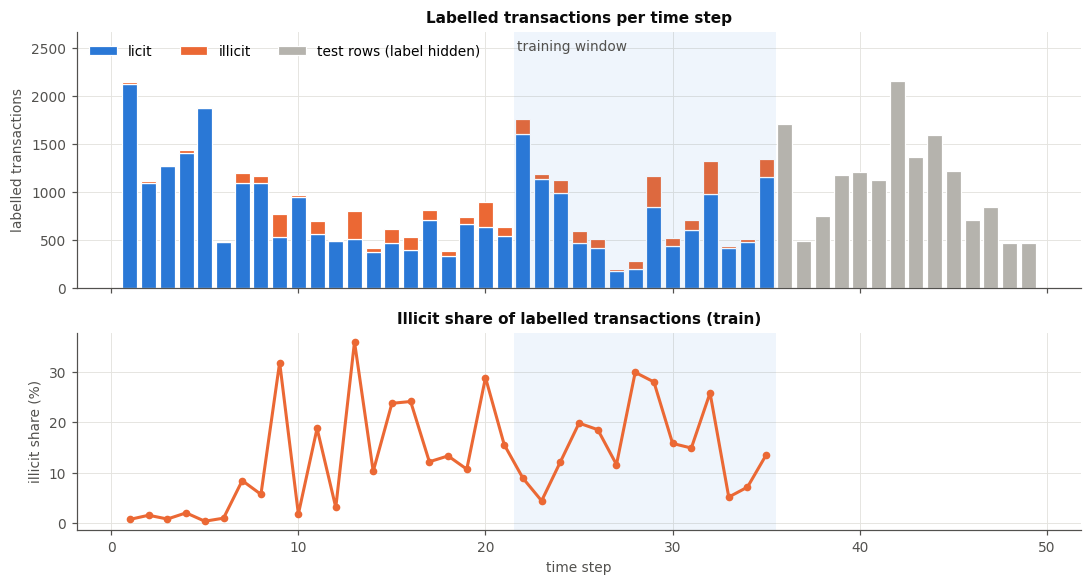

illicit share per step: 0.43% (step 5) to 35.97% (step 13), a 85x swing


In [3]:
def label_counts_by_step(frame: pd.DataFrame) -> pd.DataFrame:
    # Licit / illicit counts and illicit share per time step, over labelled rows
    labelled = frame[frame.label.notna()]
    counts = labelled.groupby(["time_step", "label"]).size().unstack(fill_value=0).rename(columns={0.0: "licit", 1.0: "illicit"})
    counts["illicit_share"] = counts.illicit / (counts.licit + counts.illicit)
    return counts


def plot_labels_over_time(by_step: pd.DataFrame, test_rows: pd.Series, window: Tuple[int, int]) -> None:
    # Two panels on one time axis (counts, then illicit share), the training window shaded in both
    fig, (ax_n, ax_rate) = plt.subplots(2, 1, figsize=(10, 5.4), sharex=True, gridspec_kw=dict(height_ratios=[1.3, 1]))
    bar = dict(width=0.8, edgecolor="white", linewidth=0.8)
    ax_n.bar(by_step.index, by_step.licit, color=BLUE, label="licit", **bar)
    ax_n.bar(by_step.index, by_step.illicit, bottom=by_step.licit, color=ORANGE, label="illicit", **bar)
    ax_n.bar(test_rows.index, test_rows.values, color=GREY, label="test rows (label hidden)", **bar)
    ax_n.set_ylabel("labelled transactions")
    ax_n.set_title("Labelled transactions per time step")
    ax_n.set_ylim(top=ax_n.get_ylim()[1] * 1.18)   # headroom for the legend
    ax_n.legend(loc="upper left", ncol=3)
    ax_rate.plot(by_step.index, 100 * by_step.illicit_share, color=ORANGE, lw=2, marker="o", ms=4)
    ax_rate.set_ylabel("illicit share (%)")
    ax_rate.set_xlabel("time step")
    ax_rate.set_title("Illicit share of labelled transactions (train)")
    for ax in (ax_n, ax_rate):
        ax.axvspan(window[0] - 0.5, window[1] + 0.5, color=BLUE, alpha=0.07, lw=0)
    ax_n.text(window[0] - 0.3, ax_n.get_ylim()[1] * 0.97, "training window", color=INK_MUTED, va="top")
    fig.tight_layout()
    plt.show()


train_by_step = label_counts_by_step(train)
last_step = train.time_step.max()
plot_labels_over_time(train_by_step, test.groupby("time_step").size(), (last_step - CONFIG["window_steps"] + 1, last_step))
share = train_by_step.illicit_share
print(f"illicit share per step: {share.min():.2%} (step {share.idxmin()}) to {share.max():.2%} (step {share.idxmax()}), "
      f"a {share.max() / share.min():.0f}x swing")

Two consequences shape the rest of the notebook:

- **Imbalance.** Overall 11.7% of labelled transactions are illicit, but the share runs from 0.4% to 36% depending on
  the step. Resampling or re-weighting to a fixed ratio would encode one period's base rate; section 2.4 explains why
  the final model trains on the natural distribution.
- **Drift.** Validation must split by time (section 2.6), and recent steps may describe the test period better than
  old ones. The shaded window is the training data actually used:

**Training rows: the last 14 steps.** On the public leaderboard, the same LightGBM recipe trained on the last
7 / 10 / **14** / 21 / all 35 steps scored 0.9283 / 0.9339 / **0.9484** / 0.9462 / 0.9437 *(recorded)*; soft
down-weighting of old steps (half-life 5 steps) was level with the window once the neighbour features were added
(0.9523 vs 0.9526). Historical validation preferred *more* history at every horizon; the leaderboard decided this
choice (section 2.6 discusses why).

## 1.3 Removing six features that identify the time period

Adversarial validation (a classifier trained to tell training rows from test rows) separated the two sets almost
perfectly, and six single features did it on their own with AUC 0.99–1.00 *(recorded)*. The cell below shows why:
each tracks the time step, and three of them take test values that never occur in training.

,spearman_with_time_step,test_share_outside_train_range
feat_100,0.992,0.992
feat_101,0.997,0.995
feat_103,0.995,0.994
feat_136,0.994,0.000
feat_137,0.896,0.000
feat_139,0.954,0.000


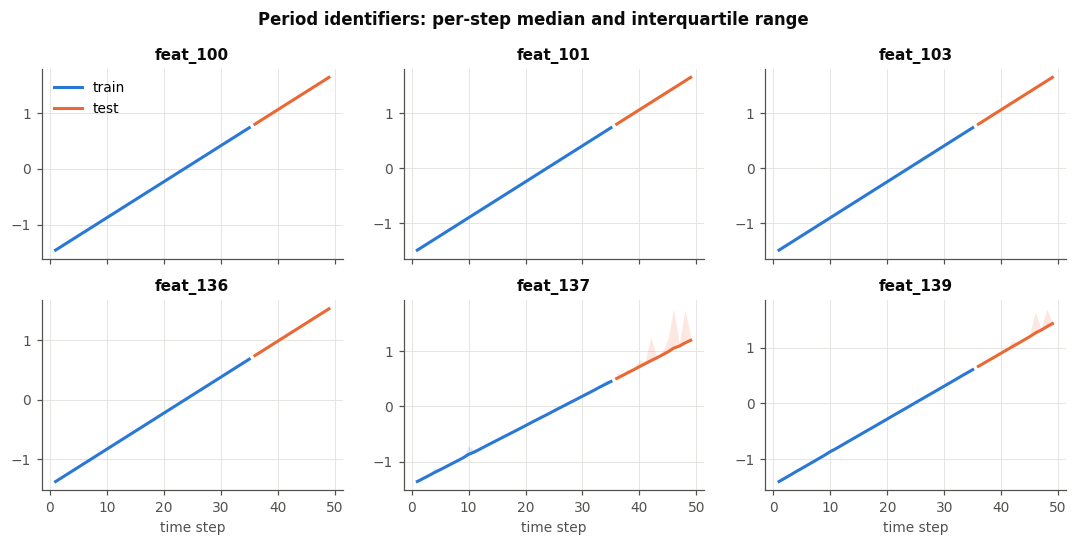

159 features kept


In [4]:
PERIOD_IDENTIFIERS = ["feat_100", "feat_101", "feat_103", "feat_136", "feat_137", "feat_139"]
FEATURES = [c for c in RAW_FEATURES if c not in PERIOD_IDENTIFIERS]


def period_identifier_evidence(train: pd.DataFrame, test: pd.DataFrame, columns: Sequence[str]) -> pd.DataFrame:
    # Rank correlation with time_step on train, and the share of test values outside the training range
    outside = {c: ((test[c] < train[c].min()) | (test[c] > train[c].max())).mean() for c in columns}
    return pd.DataFrame({
        "spearman_with_time_step": train[list(columns)].corrwith(train.time_step, method="spearman"),
        "test_share_outside_train_range": pd.Series(outside),
    }).round(3)


def plot_feature_by_step(train: pd.DataFrame, test: pd.DataFrame, columns: Sequence[str]) -> None:
    # Per-step median with the interquartile band, train and test, one small panel per feature
    fig, axes = plt.subplots(2, 3, figsize=(10, 5), sharex=True)
    for ax, col in zip(axes.flat, columns):
        for frame, colour, name in ((train, BLUE, "train"), (test, ORANGE, "test")):
            q = frame.groupby("time_step")[col].quantile([0.25, 0.5, 0.75]).unstack()
            ax.fill_between(q.index, q[0.25], q[0.75], color=colour, alpha=0.15, lw=0)
            ax.plot(q.index, q[0.5], color=colour, lw=2, label=name)
        ax.set_title(col)
    for ax in axes[-1]:
        ax.set_xlabel("time step")
    axes.flat[0].legend(loc="best")
    fig.suptitle("Period identifiers: per-step median and interquartile range", fontweight="bold", color=INK)
    fig.tight_layout()
    plt.show()


display(period_identifier_evidence(train, test, PERIOD_IDENTIFIERS))
plot_feature_by_step(train, test, PERIOD_IDENTIFIERS)
print(f"{len(FEATURES)} features kept")

A tree splitting on these columns learns *when* a transaction happened rather than *what* it looks like, and at
test time the out-of-range values all fall into the last training bin. All six are removed everywhere. Keeping them
read +0.002 on the public leaderboard, inside the noise *(recorded)*; re-entering them as deviations from their
step median cost −0.004 on validation. `time_step` itself is never a model input either: it is used only to select
rows and to build validation folds.

**Drift remains in the kept features.** Removing the six identifiers does not remove drift. The same test, run on
each of the 159 kept features (a one-feature tree model asked to tell labelled training rows from test rows, scored
out of fold: 0.5 = no difference, 1.0 = the feature alone gives the period away), finds features whose values have
moved between the training and test periods without identifying the step outright:


In [5]:
from sklearn.model_selection import StratifiedKFold


def single_feature_adversarial_auc(train_rows: pd.DataFrame, test_rows: pd.DataFrame, columns: Sequence[str],
                                   seed: int = 0) -> pd.Series:
    # Out-of-fold AUC of a one-feature LightGBM separating training rows (0) from test rows (1), per column. A small
    # tree, unlike a rank test, also catches shifts that are not monotone.
    X = pd.concat([train_rows[list(columns)], test_rows[list(columns)]], ignore_index=True)
    is_test = np.r_[np.zeros(len(train_rows)), np.ones(len(test_rows))]
    folds = list(StratifiedKFold(3, shuffle=True, random_state=seed).split(X, is_test))
    auc = {}
    for col in columns:
        oof = np.zeros(len(X))
        for fit_idx, score_idx in folds:
            tree = lgb.LGBMClassifier(n_estimators=40, learning_rate=0.1, num_leaves=15, min_child_samples=50,
                                      verbose=-1, n_jobs=-1).fit(X.iloc[fit_idx][[col]], is_test[fit_idx])
            oof[score_idx] = tree.predict_proba(X.iloc[score_idx][[col]])[:, 1]
        auc[col] = roc_auc_score(is_test, oof)
    return pd.Series(auc, name="adversarial AUC").sort_values(ascending=False)


def share_above_window_p90(train_rows: pd.DataFrame, test_rows: pd.DataFrame, col: str, window_steps: int) -> pd.DataFrame:
    # Median of `col` per period and the share of rows above the training window's 90th percentile (10% by definition
    # inside the window): how far the feature's values have moved by the test period
    window = train_rows.time_step > train_rows.time_step.max() - window_steps
    p90 = train_rows.loc[window, col].quantile(0.9)
    periods = {"train, steps 1-10": train_rows[train_rows.time_step <= 10],
               "train, steps 11-21": train_rows[train_rows.time_step.between(11, 21)],
               "train, steps 22-35 (window)": train_rows[window],
               "test, steps 36-42": test_rows[test_rows.time_step <= 42],
               "test, steps 43-49": test_rows[test_rows.time_step >= 43]}
    return pd.DataFrame({"median": {k: v[col].median() for k, v in periods.items()},
                         "share above window p90": {k: (v[col] > p90).mean() for k, v in periods.items()}}).round(3)


labelled_rows = train[train.label.notna()]
drift_auc = single_feature_adversarial_auc(labelled_rows, test, FEATURES)
print(f"kept features with adversarial AUC > 0.85: {(drift_auc > 0.85).sum()}; > 0.75: {(drift_auc > 0.75).sum()} "
      f"of {len(FEATURES)}")
display(drift_auc.head(8).round(3).to_frame())
share_above_window_p90(labelled_rows, test, "feat_2", CONFIG["window_steps"])


kept features with adversarial AUC > 0.85: 5; > 0.75: 12 of 159


,adversarial AUC
feat_2,0.935
feat_106,0.903
feat_107,0.876
feat_109,0.876
feat_142,0.853
feat_115,0.817
feat_143,0.799
feat_151,0.793


,median,share above window p90
"train, steps 1-10",-0.185,0.030
"train, steps 11-21",-0.159,0.048
"train, steps 22-35 (window)",-0.118,0.099
"test, steps 36-42",0.017,0.280
"test, steps 43-49",0.031,0.317


`feat_2`, the sixth most important feature, shows what this means for a tree. Inside the training window 10% of rows
lie above its 90th percentile by definition; in the test period about 30% do. A split learned at an exact value of
`feat_2` in steps 22–35 therefore sends a third of the test rows to the side that held only the window's top tenth.

Two ways of removing this drift were tried and both lost on the public leaderboard *(recorded)*: replacing drifting
features by their within-step percentile rank (−0.002), and dropping the five features above 0.85 (−0.0025), although
the second had the largest validation gain of any change (+0.032 on the horizon fold). The features carry signal the
model needs, so they stay. What did help was changing how model B splits on them: random split thresholds
(`extra_trees`, section 2.3). Our hypothesis is that cut-points drawn at random are less
tied to where the training period's values happen to sit.

## 1.4 The transaction graph

An edge `txId1 → txId2` means money flows from one transaction into the next. Three structural facts decide which
graph features are possible:

In [6]:
def edges_within(edges: pd.DataFrame, nodes) -> pd.DataFrame:
    # Edges whose two endpoints are both in `nodes`
    return edges[edges.txId1.isin(nodes) & edges.txId2.isin(nodes)]


def graph_facts(train: pd.DataFrame, test: pd.DataFrame, edges: pd.DataFrame) -> pd.Series:
    # Which edges join which rows: across time steps, across the train/test split, to ids with no feature row
    step = pd.concat([train[["txId", "time_step"]], test[["txId", "time_step"]]]).set_index("txId").time_step
    known = edges_within(edges, step.index)
    step_from, step_to = step.reindex(known.txId1).to_numpy(), step.reindex(known.txId2).to_numpy()
    in_test = set(test.txId)
    dangling = edges[~(edges.txId1.isin(step.index) & edges.txId2.isin(step.index))]
    return pd.Series({
        "edges": len(edges),
        "edges between rows of train/test": len(known),
        "  of which cross a time step": int((step_from != step_to).sum()),
        "  of which join train to test": int((known.txId1.isin(in_test) != known.txId2.isin(in_test)).sum()),
        "edges with an endpoint absent from both files": len(dangling),
        "  of which touch a train row": int((dangling.txId1.isin(train.txId) | dangling.txId2.isin(train.txId)).sum()),
    })


def label_homophily(train: pd.DataFrame, edges: pd.DataFrame) -> pd.Series:
    # How often linked labelled transactions share a label, against random labels within each step
    labelled = train.loc[train.label.notna()].set_index("txId")
    e = edges_within(edges, labelled.index)
    a, b = labelled.label.reindex(e.txId1).to_numpy(), labelled.label.reindex(e.txId2).to_numpy()
    p = labelled.groupby("time_step").label.mean()                    # illicit share per step
    expected_mixed = (2 * p * (1 - p)).reindex(labelled.time_step.reindex(e.txId1)).to_numpy()
    ends, other = np.r_[a, b], np.r_[b, a]                              # both directions: neighbour label given own label
    return pd.Series({
        "edges between labelled transactions": len(e),
        "share joining illicit and licit (observed)": round((a != b).mean(), 3),
        "share expected if labels were random within each step": round(expected_mixed.mean(), 3),
        "P(neighbour illicit | transaction illicit)": round(other[ends == 1].mean(), 3),
        "P(neighbour illicit | transaction licit)": round(other[ends == 0].mean(), 3),
    }, dtype=object)


display(graph_facts(train, test, edges).to_frame("count"))
display(label_homophily(train, edges).to_frame("value"))

,count
edges,234355
edges between rows of train/test,175918
of which cross a time step,0
of which join train to test,0
edges with an endpoint absent from both files,58437
of which touch a train row,0


,value
edges between labelled transactions,23900
share joining illicit and licit (observed),0.053
share expected if labels were random within each step,0.181
P(neighbour illicit | transaction illicit),0.574
P(neighbour illicit | transaction licit),0.028


- **Edges never cross a time step, and no edge joins a training row to a test row.** Label propagation from training
  labels into the test period is impossible on structural grounds, and every graph quantity for a test transaction
  must be computed from the test period alone. Edges to ids with no feature row only touch test rows, so "neighbours
  without features" would not mean the same thing in training and test; the final features ignore them.
- **Linked transactions share labels.** An illicit transaction's labelled neighbours are illicit far more often than
  a licit transaction's (57% against 3%), and illicit–licit edges are less than a third as common as random labels
  within each step would make them. This is the case for using *what the neighbours look like* as evidence about a
  transaction.

**Graph features that were tried and dropped** *(recorded)*: node topology (in/out degree, count of featureless
neighbours, DAG depth, PageRank, component size) and neighbour aggregates of raw features added to a single model.
Topology did not improve validation (0.9725 vs 0.9726), and an ablation with edges *randomly rewired within each step*
scored the same as the real graph (0.9741): degree-type structure carries no signal beyond the features. Component
size identifies the step (adversarial AUC 1.0) and was removed for the same reason as the six features above.

## 1.5 Feature engineering: neighbour features

The graph helps when it carries information *about the neighbours* rather than about the graph's shape. For every
transaction, two families of columns are built over its **labelled** incoming neighbours (transactions that paid
into it) and, separately, its labelled outgoing neighbours (transactions it paid into); direction is kept because a
payment's source and destination mean different things.

| family | columns | definition |
|---|---|---|
| neighbour scores | `nb_in_mean`, `nb_in_max`, `nb_in_n`, `nb_out_*` (6) | mean and max of a first model's illicit score over the neighbours, and their count (the labelled in/out degree) |
| neighbour feature means | `nbf_in_mean_feat_k`, `nbf_out_mean_feat_k` (2 × 159 = 318) | mean of each kept raw feature over the same neighbours |

The scores come from **model A**, a first-stage classifier, so the neighbour-score columns are a *learned* feature
extraction: they compress each neighbour's 159 features into one number that is directly about fraud. Section 2
explains how the scores are produced without leaking labels. Only labelled transactions count as neighbours on both
sides because the test file holds labelled transactions only; with all transactions as neighbours the columns
would mean something different in training than at test time.

In [7]:
def neighbour_score_stats(tx: np.ndarray, scores: np.ndarray, edges: pd.DataFrame) -> pd.DataFrame:
    # Mean, max and count of `scores` over each transaction's incoming and outgoing neighbours among `tx`
    score = pd.Series(scores, index=tx)
    e = edges_within(edges, score.index)
    columns = {}
    for side, source, target in (("in", "txId1", "txId2"), ("out", "txId2", "txId1")):
        stats = e.assign(v=score.reindex(e[source]).to_numpy()).groupby(target).v.agg(["mean", "max", "size"]).reindex(tx)
        columns[f"nb_{side}_mean"] = stats["mean"].to_numpy()
        columns[f"nb_{side}_max"] = stats["max"].to_numpy()
        columns[f"nb_{side}_n"] = stats["size"].fillna(0).to_numpy()
    return pd.DataFrame(columns)


def neighbour_feature_means(values: pd.DataFrame, edges: pd.DataFrame) -> pd.DataFrame:
    # Mean of every column of `values` (indexed by txId) over each row's incoming and outgoing neighbours among its rows
    e = edges_within(edges, values.index)
    parts = []
    for side, source, target in (("in", e.txId1, e.txId2), ("out", e.txId2, e.txId1)):
        means = values.reindex(source).set_axis(target.to_numpy()).groupby(level=0).mean()
        parts.append(means.reindex(values.index).add_prefix(f"nbf_{side}_mean_"))
    return pd.concat(parts, axis=1).reset_index(drop=True)


def model_b_inputs(X: pd.DataFrame, tx: np.ndarray, scores: np.ndarray, edges: pd.DataFrame,
                   nb_features: Sequence[str]) -> pd.DataFrame:
    # Model B's design matrix: the raw features, the 6 neighbour-score columns, the neighbour feature means.
    # The neighbourhood is the rows of X themselves, so pass only labelled rows.
    values = pd.DataFrame(X[list(nb_features)].to_numpy(), index=tx, columns=list(nb_features))
    return pd.concat([X.reset_index(drop=True), neighbour_score_stats(tx, scores, edges),
                      neighbour_feature_means(values, edges)], axis=1)

**Why these and not others** *(recorded, public leaderboard unless noted)*:

- Neighbour *scores* added to the model: +0.004 (0.9484 → 0.9526); variants with min / std, two-hop neighbours,
  or a second pass of the same idea were level or worse — six numbers capture what the next model can use.
- Neighbour *feature means* on top of the scores: the top-10 features +0.0022 (0.95849 → 0.96069), all 159 a further
  +0.0011. The same aggregates had *lowered* validation by 0.008 when added to a single model without the scores;
  beside the scores they help. Max, deltas, score-weighted means and two-hop means all ranked the test rows almost
  the same way as the means (Spearman ≥ 0.988), so the plain mean is kept.
- Wider neighbourhoods lost on the leaderboard every time: Louvain communities −0.0034, GraphSAGE embeddings −0.005,
  smoothing the final score along edges −0.012. The usable graph signal on the test period is the labelled one-hop
  neighbourhood.

## 1.6 Feature selection, scaling and augmentation

- **Selection.** 159 of the 165 raw features (section 1.3) plus 6 + 318 neighbour columns = 483 model-B inputs.
  No further selection: dropping the aggregated block (`feat_94`+) cost −0.012 on the leaderboard, and the column
  blocks are used instead as an ensemble (section 2.2).
- **Scaling.** None: tree models are invariant to monotone transformations. Replacing drifting features by their
  within-step percentile rank helped the far validation fold (+0.02) and lost on the leaderboard (−0.002).
- **Augmentation.** No synthetic samples. Pseudo-labels (confident test rows of steps 36–42, or unlabelled
  training rows) were tried as extra training rows and lost (−0.005 and −0.006).

The labelled training rows used by everything below:

In [8]:
labelled = train[train.label.notna()].reset_index(drop=True)
X_all, X_test = labelled[FEATURES], test[FEATURES]
y_all = labelled.label.to_numpy().astype(int)
ts_all = labelled.time_step.to_numpy()
tx_train, tx_test = labelled.txId.to_numpy(), test.txId.to_numpy()

in_window = ts_all > ts_all.max() - CONFIG["window_steps"]
print(f"labelled training rows: {len(labelled):,}; in the {CONFIG['window_steps']}-step window: {in_window.sum():,} "
      f"({y_all[in_window].mean():.1%} illicit); test rows: {len(test):,}")

labelled training rows: 31,235; in the 14-step window: 11,705 (15.1% illicit); test rows: 15,329


# 2. Model development and validation

## 2.1 The two-stage model

| stage | model | trained on | produces |
|---|---|---|---|
| A | LightGBM, 31 leaves, 300 rounds | labelled rows of the window, 159 features | an illicit score for every transaction (training rows: out of fold) |
| neighbour features | – | model-A scores and raw features of labelled neighbours | 6 + 318 columns (section 1.5) |
| B | LightGBM, 15 leaves, 300 rounds, random split thresholds, two variants × three class weightings | the same rows, 483 columns | the final probability |

**Out-of-fold scoring, and the leak it must avoid.** If model A scored training rows it had been fitted on, their
scores would be nearly perfect, model B would learn to trust neighbour scores far more than it should, and the trust
would fail on the test rows (whose neighbours model A never saw). So the window's rows are split into 5 folds and each
row is scored by a model fitted on the other four. A random split is not enough: a row's neighbour sits in another
fold, and the model scoring that neighbour was trained on the row itself, so the row's own label leaks into its
neighbour-score columns (the outgoing neighbour mean reached validation AUC 0.902 under random folds, 0.889 without
the leak *(recorded)*). The folds therefore keep each **connected component** of the labelled window graph together:
no model that scores a neighbour has seen the row.

The protocol's history *(recorded, public)*: time-ordered scoring (step *s* scored by a model on steps before *s*)
0.95621 → random folds 0.95849, because a scorer that has seen the row's own period resembles the test scorer, which
is fitted on the whole window; random → grouped folds 0.96313 → 0.96310 on 15 seeds, a tie on the board, adopted
because it removes a known leak and validates higher on both seed pairs tried.

In [9]:
def make_lgbm(params: dict, seed: int) -> lgb.LGBMClassifier:
    return lgb.LGBMClassifier(**params, random_state=seed)


def connected_component_ids(tx: np.ndarray, edges: pd.DataFrame) -> np.ndarray:
    # Component id of each transaction in the graph restricted to `tx`, ignoring edge direction
    position = pd.Series(np.arange(len(tx)), index=tx)
    e = edges_within(edges, position.index)
    adjacency = sp.coo_matrix((np.ones(len(e)), (position[e.txId1].to_numpy(), position[e.txId2].to_numpy())),
                              shape=(len(tx), len(tx)))
    return connected_components(adjacency, directed=False)[1]


def model_a_oof_scores(X: pd.DataFrame, y: np.ndarray, tx: np.ndarray, edges: pd.DataFrame, seed: int,
                       cfg: dict = CONFIG) -> np.ndarray:
    # Out-of-fold model-A scores; stratified folds that keep each connected component in one fold
    folds = StratifiedGroupKFold(cfg["oof_folds"], shuffle=True, random_state=seed)
    scores = np.full(len(X), np.nan)
    for fit_idx, score_idx in folds.split(X, y, groups=connected_component_ids(tx, edges)):
        model = make_lgbm(cfg["model_a"], seed).fit(X.iloc[fit_idx], y[fit_idx])
        scores[score_idx] = model.predict_proba(X.iloc[score_idx])[:, 1]
    return scores

## 2.2 Model B: two variants, three class weightings

Model B sees the 483 columns. Two variants are trained on identical inputs:

- **all columns**: one LightGBM on everything;
- **blocks**: the mean of three LightGBM fits that see (i) all columns, (ii) the local block `feat_1`–`feat_93` plus the
  neighbour columns, (iii) the aggregated block `feat_94`+ plus the neighbour columns. Forcing two of the three fits
  to work without one feature block makes them find different splits.

Both use random split thresholds (section 2.3). They score close on the leaderboard (all columns 0.96678 / 0.96736 on
two independent seed sets, blocks 0.96630 *(recorded)*) but rank the test rows differently (Spearman 0.95), which is
what makes their average worth more than either (section 3.3). Each variant is fitted under three class weightings
(section 2.4), which gives six members. The final score is the equal-weight average of the six members' **ranks**
over the whole test set: ROC AUC depends only on order, and ranks put the members on the same scale.

In [10]:
def model_b_all_columns(XB_fit: pd.DataFrame, y_fit: np.ndarray, XB_new: pd.DataFrame, seed: int,
                        cfg: dict = CONFIG, sample_weight: np.ndarray = None) -> np.ndarray:
    return make_lgbm(cfg["model_b"], seed).fit(XB_fit, y_fit, sample_weight=sample_weight).predict_proba(XB_new)[:, 1]


def model_b_blocks(XB_fit: pd.DataFrame, y_fit: np.ndarray, XB_new: pd.DataFrame, seed: int,
                   cfg: dict = CONFIG, sample_weight: np.ndarray = None) -> np.ndarray:
    # Mean of model-B fits on all columns / local block + neighbour columns / aggregated block + neighbour columns
    raw = [c for c in XB_fit.columns if c.startswith("feat_")]
    neighbour = [c for c in XB_fit.columns if not c.startswith("feat_")]
    local = [c for c in raw if int(c.split("_")[1]) <= cfg["local_block_last"]]
    aggregated = [c for c in raw if c not in local]
    blocks = [list(XB_fit.columns), local + neighbour, aggregated + neighbour]
    return np.mean([model_b_all_columns(XB_fit[cols], y_fit, XB_new[cols], seed, cfg, sample_weight) for cols in blocks],
                   axis=0)


def per_step_class_weights(y: np.ndarray, ts: np.ndarray) -> np.ndarray:
    # Each illicit row weighted by its own step's licit/illicit ratio; licit rows weight 1
    y = np.asarray(y, float)
    rate = pd.Series(y).groupby(np.asarray(ts)).transform("mean").to_numpy()
    return np.where(y == 1, (1 - rate) / rate, 1.0)


MODEL_B_VARIANTS: Dict[str, Callable[..., np.ndarray]] = {"all_columns": model_b_all_columns, "blocks": model_b_blocks}
# One member per (variant, class weight), e.g. "blocks | weight 12"
MEMBERS = [f"{variant} | {weight}" for weight in CONFIG["class_weights"] for variant in MODEL_B_VARIANTS]


def two_stage_fit_predict(X: pd.DataFrame, y: np.ndarray, ts: np.ndarray, tx: np.ndarray, X_new: pd.DataFrame,
                          tx_new: np.ndarray, edges: pd.DataFrame, seed: int, cfg: dict = CONFIG) -> Dict[str, np.ndarray]:
    # Fit the two-stage model on the last `window_steps` steps of (X, y); return each member's (model-B variant x
    # class weight) probabilities for X_new. X_new must hold labelled rows of one period (their own neighbourhood).
    window = ts > ts.max() - cfg["window_steps"]
    X_fit, y_fit, tx_fit = X[window], y[window], tx[window]
    score_fit = model_a_oof_scores(X_fit, y_fit, tx_fit, edges, seed, cfg)
    score_new = make_lgbm(cfg["model_a"], seed).fit(X_fit, y_fit).predict_proba(X_new)[:, 1]
    XB_fit = model_b_inputs(X_fit, tx_fit, score_fit, edges, cfg["nb_features"])
    XB_new = model_b_inputs(X_new, tx_new, score_new, edges, cfg["nb_features"])
    out = {}
    for weight, spec in cfg["class_weights"].items():
        params, rows = ({}, per_step_class_weights(y_fit, ts[window])) if spec == "per_step" else (spec, None)
        cfg_w = {**cfg, "model_b": {**cfg["model_b"], **params}}
        for variant, fit in MODEL_B_VARIANTS.items():
            out[f"{variant} | {weight}"] = fit(XB_fit, y_fit, XB_new, seed, cfg_w, rows)
    return out


def rank_blend(predictions: Dict[str, np.ndarray]) -> np.ndarray:
    # Equal-weight average of pooled ranks, scaled to (0, 1]
    return np.mean([rankdata(p) / len(p) for p in predictions.values()], axis=0)

## 2.3 Hyperparameters

| parameter | model A | model B | how it was chosen |
|---|---|---|---|
| leaves | 31 | 15 | model A: conventional value, held fixed. Model B: depth read on the public board *(recorded)*: 31 → 0.9526, 23 → 0.9550, **15 → 0.9562**, 7 → 0.9550 |
| rounds × learning rate | 300 × 0.03 | 300 × 0.05 | fixed rounds, no early stopping. Model A: validation AUC plateaued at 300 rounds (150 / 200 / 300 / 400: 0.9765 / 0.9806 / **0.9819** / 0.9809). Model B: learning rate from a random search of LightGBM settings on the validation folds; 300 rounds at 15 leaves read 0.9562 vs 0.9550 for the search's 7 leaves × 600 rounds |
| row subsample | 80% | 100% | model B: from the same search (its best configurations used small trees and no row subsampling) |
| column subsample | 60% | 60% | 100% for model B validated lower and ranked the test rows almost identically (Spearman 0.992) |
| min. rows per leaf | 20 (default) | 40 | model B: from the same search |
| L2 regularisation | 1.0 | 1.0 | – |
| split thresholds | best (default) | **random** (`extra_trees`) | model B: public +0.005 on the all-columns variant (0.96209 → 0.96678, confirmed by an independent seed set at 0.96736) and +0.0025 on the blocks variant, while validation stayed level *(recorded)*. Our hypothesis: random thresholds stop model B relying on exact cut-points of the training period, which drifting features do not keep (section 1.3). Around it: 600 rounds −0.0032 on the public board; 31 leaves, 63 bins, 40% columns and random column halves validated lower or ranked the test rows like it (Spearman ≥ 0.98) |
| class weight | none | **illicit rows up-weighted**: 5.6 (balanced), 12 and per-step balance, all three fitted and averaged | section 2.4 |
| seeds | 1 per fit | 15 per member | re-seeding a 5-seed bag moved the public score by 0.0015; a 30-seed bag scored the same as 15 |

Other learners for model B were compared like for like *(recorded, public)*: XGBoost 0.9540 and CatBoost 0.9464 vs
LightGBM 0.9562; a ranking objective (lambdarank) 0.9450. With the final inputs and the balanced class weight, XGBoost read
0.96254 against LightGBM's 0.96996, although it validated higher (+0.007 on the 3-fold mean). Forbidding model B to combine
a row's own columns with its neighbour columns in one tree (interaction constraints) read 0.96532 (−0.0046): the
interactions between what a transaction looks like and what its neighbours look like carry signal.

## 2.4 Class imbalance

The window holds 15% illicit rows. Model A trains on this natural distribution. Model B gives the illicit rows a
larger weight, and is fitted three times per variant: at the **balanced** weight (`is_unbalance`: each illicit row
counts 84.9 / 15.1 ≈ 5.6 times, so both classes carry the same total weight), at weight 12 (about twice that, an
exploration point rather than a value derived from the data), and with **per-step balance** (each illicit row weighted
by its own step's licit/illicit ratio, 2.3 in step 28 to 21 in step 23, so fraud in the low-rate steps counts most). ROC AUC depends only on the order of the scores, so a
class weight cannot improve it directly; it changes which splits the 15-leaf trees spend their capacity on, pushing
them to separate the illicit region more finely.

Evidence *(recorded)*: on the public leaderboard (all-columns variant, 5 seeds) weight 1 → 0.9671 (two seed sets),
5.6 → 0.96996, 12 → 0.96917, per-step → 0.96954; the two-variant blend rose from 0.96828 unweighted to 0.97020 at the
balanced weight, 0.97032 averaged over two weightings and 0.97066 over all three. Focal loss (γ = 2, the same class
weight, rows already scored right down-weighted) read 0.96688 (−0.0031 against the balanced weight), the unweighted level:
it weakens the up-weighting of the illicit rows that the trees already separate. Validation did not see it: the weighted models validate level or slightly lower
(section 2.6), and early in the project `scale_pos_weight` together with early stopping had cost about 0.006 AUC on the
hardest fold. As with random split thresholds, the choice therefore rests on the leaderboard. Averaging over the three weightings,
rather than picking the one with the best public reading (they lie within 0.0008, inside seed noise), keeps the choice
from fitting the public 30% of the test set. Our hypothesis, not a measured mechanism: illicit transactions are
rarer in the test period (section 3.4), and a model that has spent more of its splits on the illicit profile still ranks
those rare cases above the licit ones.

Early stopping is not used: tuned on the most recent part of a window, it adapts the number of rounds to that tail's
base rate, which differs from the next period's (section 1.2). Besides ROC AUC the validation reports PR-AUC, which is
sensitive to how the rare class is ranked at the top.

## 2.5 Overfitting

- **Leakage control first**: out-of-fold, component-grouped scores for model A (section 2.1); `time_step` never an
  input; the six period identifiers removed; validation strictly forward in time.
- **Capacity**: fixed 300 rounds, 15-leaf trees for model B (deeper trees scored lower on the leaderboard), at least
  40 rows per leaf, 60% of columns per tree, L2 penalty, random split thresholds.
- **Variance**: 15-seed bags of each member, plus the six-member blend (two variants × three class weightings).
- **Recency**: a 14-step window instead of all history (section 1.2).

## 2.6 Validation

**Protocol.** Rolling-origin folds by time step: fit on steps up to *t*, validate on a later block the model never
saw. A random K-fold would put future transactions into the training set of past ones. Three 7-step folds, plus a
*horizon* fold that validates 14 steps ahead (the length of the test period). Inside each fold the full pipeline
runs, including the 14-step window and the out-of-fold scoring. Metrics: pooled ROC AUC (the competition metric),
the mean of per-step AUCs, and PR-AUC.

In [11]:
FOLDS = [  # (first train step, last train step, first validation step, last validation step)
    (1, 14, 15, 21),
    (1, 21, 22, 28),
    (1, 28, 29, 35),
    (1, 21, 22, 35),   # horizon fold: 14 steps ahead
]


def evaluate(y: np.ndarray, p: np.ndarray, ts: np.ndarray) -> Dict[str, float]:
    per_step = [roc_auc_score(y[ts == s], p[ts == s]) for s in np.unique(ts) if len(np.unique(y[ts == s])) == 2]
    return dict(auc=roc_auc_score(y, p), auc_per_step_mean=np.mean(per_step), pr_auc=average_precision_score(y, p))


def rolling_origin_cv(X: pd.DataFrame, y: np.ndarray, ts: np.ndarray, tx: np.ndarray, edges: pd.DataFrame,
                      folds: Sequence[Tuple[int, int, int, int]], seeds: Sequence[int], cfg: dict = CONFIG) -> pd.DataFrame:
    # Validation scores of each model-B variant and of their blend, one row per (fold, seed, model)
    rows = []
    for fit_lo, fit_hi, val_lo, val_hi in folds:
        fit = (ts >= fit_lo) & (ts <= fit_hi)
        val = (ts >= val_lo) & (ts <= val_hi)
        for seed in seeds:
            preds = two_stage_fit_predict(X[fit], y[fit], ts[fit], tx[fit], X[val], tx[val], edges, seed, cfg)
            preds["blend"] = rank_blend(preds)
            for model, p in preds.items():
                rows.append(dict(model=model, fold=f"train {fit_lo}-{fit_hi} | val {val_lo}-{val_hi}", seed=seed,
                                 **evaluate(y[val], p, ts[val])))
    return pd.DataFrame(rows)


def summarise_cv(cv: pd.DataFrame, folds: Sequence[Tuple[int, int, int, int]]) -> pd.DataFrame:
    # Headline numbers per model: mean of the three 7-step folds, the hard fold, the horizon fold
    by_fold = cv.groupby(["model", "fold"])[["auc", "pr_auc"]].mean()
    name = lambda f: f"train {f[0]}-{f[1]} | val {f[2]}-{f[3]}"
    three, hard, horizon = [name(f) for f in folds[:3]], name(folds[1]), name(folds[3])
    return pd.DataFrame({
        "AUC, mean of 3 folds": by_fold.auc.unstack().loc[:, three].mean(axis=1),
        "AUC, fold 22-28": by_fold.auc.unstack()[hard],
        "AUC, horizon 22-35": by_fold.auc.unstack()[horizon],
        "PR-AUC, mean of 3 folds": by_fold.pr_auc.unstack().loc[:, three].mean(axis=1),
    }).round(4)


MODELS = [*MEMBERS, "blend"]
cv = rolling_origin_cv(X_all, y_all, ts_all, tx_train, edges, FOLDS, CONFIG["cv_seeds"])
per_fold = cv.groupby(["fold", "model"])[["auc", "auc_per_step_mean", "pr_auc"]].mean().unstack("model")
display(per_fold.reindex(columns=MODELS, level="model").round(4))
summarise_cv(cv, FOLDS).loc[MODELS]

auc                    \
model                  all_columns | balanced blocks | balanced   
fold                                                              
train 1-14 | val 15-21                 0.9930            0.9915   
train 1-21 | val 22-28                 0.9020            0.8980   
train 1-21 | val 22-35                 0.8050            0.7996   
train 1-28 | val 29-35                 0.9982            0.9980   

                                                                   \
model                  all_columns | weight 12 blocks | weight 12   
fold                                                                
train 1-14 | val 15-21                  0.9928             0.9919   
train 1-21 | val 22-28                  0.9106             0.8984   
train 1-21 | val 22-35                  0.8173             0.8026   
train 1-28 | val 29-35                  0.9982             0.9980   

                                                                         \
model                  all_columns | per-step blocks | per-step   blend   
fold                                                                      
train 1-14 | val 15-21                 0.9922            0.9913  0.9933   
train 1-21 | val 22-28                 0.9044            0.8969  0.9020   
train 1-21 | val 22-35                 0.8089            0.7989  0.8030   
train 1-28 | val 29-35                 0.9981            0.9980  0.9983   

                            auc_per_step_mean                    \
model                  all_columns | balanced blocks | balanced   
fold                                                              
train 1-14 | val 15-21                 0.9926            0.9914   
train 1-21 | val 22-28                 0.9106            0.9078   
train 1-21 | val 22-35                 0.8731            0.8706   
train 1-28 | val 29-35                 0.9970            0.9964   

                                                ...                         \
model                  all_columns | weight 12  ... all_columns | per-step   
fold                                            ...                          
train 1-14 | val 15-21                  0.9924  ...                 0.9919   
train 1-21 | val 22-28                  0.9166  ...                 0.9118   
train 1-21 | val 22-35                  0.8800  ...                 0.8758   
train 1-28 | val 29-35                  0.9970  ...                 0.9970   

                                                                 pr_auc  \
model                  blocks | per-step   blend all_columns | balanced   
fold                                                                      
train 1-14 | val 15-21            0.9911  0.9929                 0.9818   
train 1-21 | val 22-28            0.9073  0.9106                 0.8622   
train 1-21 | val 22-35            0.8703  0.8729                 0.7865   
train 1-28 | val 29-35            0.9965  0.9971                 0.9934   

                                                                  \
model                  blocks | balanced all_columns | weight 12   
fold                                                               
train 1-14 | val 15-21            0.9783                  0.9818   
train 1-21 | val 22-28            0.8567                  0.8634   
train 1-21 | val 22-35            0.7835                  0.7884   
train 1-28 | val 29-35            0.9931                  0.9934   

                                                                  \
model                  blocks | weight 12 all_columns | per-step   
fold                                                               
train 1-14 | val 15-21             0.9788                 0.9800   
train 1-21 | val 22-28             0.8575                 0.8628   
train 1-21 | val 22-35             0.7842                 0.7870   
train 1-28 | val 29-35             0.9929                 0.9932   

                                                  
model         

,"AUC, mean of 3 folds","AUC, fold 22-28","AUC, horizon 22-35","PR-AUC, mean of 3 folds"
model,,,,
all_columns | balanced,0.9644,0.9020,0.8050,0.9458
blocks | balanced,0.9625,0.8980,0.7996,0.9427
all_columns | weight 12,0.9672,0.9106,0.8173,0.9462
blocks | weight 12,0.9628,0.8984,0.8026,0.9431
all_columns | per-step,0.9649,0.9044,0.8089,0.9453
blocks | per-step,0.9621,0.8969,0.7989,0.9424
blend,0.9645,0.9020,0.8030,0.9460


**Reading the validation numbers.** The pipeline is sound: 0.99+ on the two easy folds, no sign of leakage (an
in-sample leak would push every fold towards 1.0). Step 22–28 is the hard fold, and 14 steps ahead the AUC drops
to about 0.81: drift is the main difficulty. On these folds the six members and the blend are level (3-fold means
0.962–0.967); the class weightings and the blend are not separated by validation.

The validation folds were a reliable guide for *features* and a poor one for *temporal* choices. They preferred all
history over the 14-step window and a single model over the two-stage model, and both preferences lost on the public
leaderboard; on the one large feature decision (dropping the aggregated block) the two agreed. The reason is visible
in section 3.4: the test period behaves unlike any training window (from step 43 on, every model predicts almost
no fraud). The folds therefore serve as a sanity check (a candidate must reach 0.95 on the 3-fold mean) and the
leaderboard decides temporal and ensembling questions, with the safeguards described in section 3.2.

# 3. Model exploration and final strategy

## 3.1 What was explored

One row per decisive experiment, in the order they were run. Validation = the protocol of section 2.6 (3-fold mean
and horizon fold); public = public leaderboard (30% of the test rows). All numbers *(recorded)*.

| stage | model / change | val. 3-fold | val. horizon | public | outcome |
|---|---|---|---|---|---|
| single model, all history | logistic regression (standardised, balanced) | 0.909 | 0.828 | – | far below trees |
| | random forest | 0.962 | 0.816 | 0.9285 | rejected |
| | ExtraTrees | 0.965 | 0.825 | – | rejected |
| | **LightGBM** (31 leaves, 300 rounds, 5 seeds) | 0.981 | 0.897 | 0.9437 | reference recipe |
| | + graph topology features | no gain | – | unreadable | rejected (section 1.4) |
| | GraphSAGE / MLP, strictly inductive | 0.950 / 0.953 | 0.859 / 0.883 | – | ≈ 0.03 below LightGBM; rewired edges score the same |
| training rows | LightGBM, last 14 steps | 0.979 | 0.880 | **0.9484** | adopted (7 / 10 / 21 steps: 0.9283 / 0.9339 / 0.9462) |
| two-stage | + neighbour scores, model B 31 leaves | 0.974 | 0.848 | **0.9526** | adopted |
| | model B 15 leaves | 0.972 | 0.836 | **0.9562** | adopted |
| | model B = XGBoost / CatBoost | 0.967 / 0.968 | 0.817 / 0.832 | 0.9540 / 0.9464 | rejected |
| | training rows scored by random folds | 0.973 | 0.842 | **0.9585** | adopted |
| | + neighbour feature means, top-10 features | 0.969 | 0.822 | **0.9607** | adopted |
| | + neighbour feature means, all 159 features | 0.963 | 0.802 | **0.9618** | adopted |
| | + GraphSAGE embeddings into model B | 0.961 | 0.802 | 0.9557 | rejected |
| | + Louvain community scores | 0.977 | 0.851 | 0.9573 | rejected |
| | + pseudo-labelled test rows | 0.964 | 0.807 | 0.9555 | rejected |
| | component-grouped folds, 15 seeds | 0.966 | 0.811 | **0.9631** | adopted: variant "all columns" |
| | block-ensemble model B, 15 seeds | 0.966 | 0.817 | **0.9639** | adopted: variant "blocks" |
| | rank average of the two variants | 0.966 | 0.812 | **0.9654** | adopted, then superseded |
| | drop the 5 most drifting features (adversarial AUC > 0.85) | 0.971 | 0.843 | 0.9596 | rejected: largest validation gain, lost on the board |
| | **random split thresholds in model B** (`extra_trees`), all columns, 5 / 10 seeds | 0.965 | 0.812 | **0.9668 / 0.9674** | adopted: variant "all columns" |
| | random split thresholds, blocks variant | 0.963 | 0.803 | **0.9663** | adopted: variant "blocks" |
| | rank average of the two variants, 15 seeds each | – | – | **0.9683** | adopted, then superseded |
| | **class weight in model B**: balanced (5.6), all columns, 5 seeds | 0.964 | 0.805 | **0.9700** | adopted |
| | class weight 12, all columns, 5 seeds | 0.967 | 0.817 | 0.9692 | adopted as the second weight |
| | rank average of the two variants at the balanced weight, 15 seeds each | – | – | **0.9702** | **second selection** (section 3.3) |
| | rank average of two variants × two class weights (5.6, 12), 15 seeds each | – | – | **0.9703** | superseded |
| | per-step class balance (fraud weight = its step's licit/illicit ratio), all columns, 5 seeds | 0.965 | 0.809 | 0.9695 | adopted as the third weighting |
| | final model with a 21-step window added (12 members) | – | – | 0.9703 | tie, not selected |
| | model B = XGBoost, balanced class weight, 15 seeds | 0.972 | 0.838 | 0.9625 | rejected (validation highest, board lowest) |
| | focal loss in model B (γ = 2), all columns, 5 seeds | 0.965 | 0.807 | 0.9669 | rejected |
| | interaction constraints: own columns vs neighbour columns, all columns, 5 seeds | 0.963 | 0.813 | 0.9653 | rejected |
| final | **rank average of two variants × three class weightings, 15 seeds each** | – | – | **0.9707** | **submitted** |

Three patterns run through the table. Gradient-boosted trees beat every other family on these tabular features,
including graph neural networks, which scored no better on the real graph than on a randomly rewired one. Every gain
after the first came from two ideas: train on what is recent, and give the model what its neighbours look like
through a first model's predictions. And from the two-stage model on, validation and the public board disagree
about the size and sometimes the sign of a change, so the comparison protocol matters as much as the models.

## 3.2 How candidates were compared

The public leaderboard is a small sample (≈ 4,600 rows) and noisy, so it was used under fixed rules:

1. **One change per submission**, against the current best file, so a difference can be attributed.
2. **Validation sanity check**: a candidate must reach 0.95 on the 3-fold mean; validation gains alone never promoted
   a candidate.
3. **Distinctness gate**: a file is submitted only if its Spearman rank correlation with every already-scored file is
   below 0.98. Files that rank the test rows almost identically return the same score plus noise and cannot answer a
   question. In the last week, near the top of the board, files ranking 0.98–0.999 like the best were also submitted
   (averaging steps and single changes expected to be small); they were read as ties unless they moved by more than the
   noise.
4. **Reading rule**: above +0.003 is a gain; within ±0.003 a tie (the simpler model wins); below −0.003 a loss. The
   threshold comes from measured seed noise (0.0015 for a re-seeded 5-seed bag).

## 3.3 Final strategy

**Final submission: the rank average of six 15-seed members, the two model-B variants each fitted under three class
weightings (5.6 = balanced, 12, per-step balance), all with random split thresholds (public 0.97066).** Each ingredient
was read on the leaderboard on its own: random thresholds lifted the two-variant blend from 0.96539 to 0.96828, the
balanced class weight to 0.97020, and averaging over the three weightings to 0.97066 (inside seed noise of 0.97020,
kept because it does not rest on one weighting chosen from public differences inside seed noise). The two variants rank the test rows differently (Spearman 0.94
under each weighting) while being nearly equally good, so averaging them cancels part of each one's errors: the blend sat
+0.0016 to +0.0019 above its members' mean each time it was measured. On the historical folds neither the blend, the
random thresholds nor the class weights rank above the plain model, so this choice rests on the leaderboard. The risk
is contained: every member is among the best single models on the board, so the blend never leans on a weaker model.

**Second selected submission: the two variants at the balanced class weight only, two members in one rank average
(public 0.97020).** It holds both gains the leaderboard confirmed, random split thresholds and up-weighted illicit rows,
at a single weighting: the final submission without its two other weightings (Spearman 0.999 with it). Setting
`CONFIG["class_weights"] = {"balanced": dict(is_unbalance=True)}` reproduces it. Other files scored for this place were
the blend without random thresholds and class weights (public 0.96539) and the final model with its six members refitted
on 21 steps (public 0.97034, `CONFIG["extra_windows"] = (21,)`).

The cell below fits the final model on all labelled rows of steps 22–35, scores the test rows with each of the 15
seeds, averages the seeds per member, blends the six members and writes the submission. When the uploaded files are
present (in `submissions/` locally, or attached on Kaggle), it checks that it reproduced each member's bag and the blend,
and stops with an error if any differs by more than 1e-9.

In [12]:
# Files scored on the public leaderboard, for the reproducibility check: each member's 15-seed bag, and the blend for
# each submitted configuration, keyed by (class weightings, extra windows)
UPLOADED_BAGS = {
    "all_columns | balanced": "fam_B15_nbfeat_all_goof_xt_unbal_bag15.csv",
    "blocks | balanced": "fam_B15_nbfeat_all_goof_blocks_xt_unbal_bag15.csv",
    "all_columns | weight 12": "fam_B15_nbfeat_all_goof_xt_spw12_bag15.csv",
    "blocks | weight 12": "fam_B15_nbfeat_all_goof_blocks_xt_spw12_bag15.csv",
    "all_columns | per-step": "fam_B15_nbfeat_all_goof_xt_stepunbal_bag15.csv",
    "blocks | per-step": "fam_B15_nbfeat_all_goof_blocks_xt_stepunbal_bag15.csv",
    "all_columns | balanced | 21 steps": "fam_B15_nbfeat_all_goof_xt_unbal_w21_bag15.csv",
    "blocks | balanced | 21 steps": "fam_B15_nbfeat_all_goof_blocks_xt_unbal_w21_bag15.csv",
    "all_columns | weight 12 | 21 steps": "fam_B15_nbfeat_all_goof_xt_spw12_w21_bag15.csv",
    "blocks | weight 12 | 21 steps": "fam_B15_nbfeat_all_goof_blocks_xt_spw12_w21_bag15.csv",
    "all_columns | per-step | 21 steps": "fam_B15_nbfeat_all_goof_xt_stepunbal_w21_bag15.csv",
    "blocks | per-step | 21 steps": "fam_B15_nbfeat_all_goof_blocks_xt_stepunbal_w21_bag15.csv",
}
UPLOADED_BLENDS = {
    (("balanced", "weight 12", "per-step"), ()): "fam_F1_wavg.csv",        # final submission
    (("balanced",), ()): "fam_F1_unbal.csv",                               # second selected submission
    (("balanced", "weight 12", "per-step"), (21,)): "fam_F1_wavg_win.csv",  # scored, not selected
}


def predict_test(seeds: Sequence[int], cfg: dict = CONFIG) -> Dict[str, np.ndarray]:
    # Seed-bagged probabilities of each member on the test rows; each extra window adds every member again, fitted on
    # that many steps and named "<member> | <k> steps"
    windows = [(cfg["window_steps"], "")] + [(k, f" | {k} steps") for k in cfg["extra_windows"]]
    per_seed = []
    for seed in seeds:
        p = {}
        for k, suffix in windows:
            fitted = two_stage_fit_predict(X_all, y_all, ts_all, tx_train, X_test, tx_test, edges, seed,
                                           {**cfg, "window_steps": k})
            p.update({name + suffix: scores for name, scores in fitted.items()})
        per_seed.append(p)
    return {name: np.mean([p[name] for p in per_seed], axis=0) for name in per_seed[0]}


def write_submission(scores: np.ndarray, path: Path) -> pd.DataFrame:
    submission = sample_submission.assign(target=scores)
    assert len(submission) == len(test) and submission.target.between(0, 1).all() and submission.target.notna().all()
    submission.to_csv(path, index=False)
    return submission


def find_uploaded(name: str) -> List[Path]:
    candidates = [Path("submissions") / name] + [Path(d) / name for d, _, _ in os.walk("/kaggle/input", followlinks=True)]
    return [p for p in candidates if p.exists()]


bags = predict_test(CONFIG["seeds"])
final_scores = rank_blend(bags)
submission = write_submission(final_scores, OUTPUT)
print(f"wrote {OUTPUT}: {len(submission):,} rows, rank average of {len(bags)} members")

blend_file = UPLOADED_BLENDS.get((tuple(CONFIG["class_weights"]), tuple(CONFIG["extra_windows"])))
if FAST or USE_GPU or blend_file is None or not all(m in UPLOADED_BAGS for m in bags):
    print("reproducibility check skipped: FAST, GPU or a configuration that was not submitted")
else:
    references = {**{m: UPLOADED_BAGS[m] for m in bags}, "blend": blend_file}
    checked = 0
    for key, file in references.items():
        paths = find_uploaded(file)
        if not paths:
            print(f"{file}: not found here, not checked")
            continue
        diff = np.abs(pd.read_csv(paths[0]).target.to_numpy() - (final_scores if key == "blend" else bags[key])).max()
        print(f"max |difference| vs uploaded {file}: {diff:.1e}")
        assert diff < 1e-9, f"{key} does not reproduce {file}"
        checked += 1
    print(f"reproduced {checked} of {len(references)} uploaded files exactly")

wrote submission.csv: 15,329 rows, rank average of 6 members
max |difference| vs uploaded fam_B15_nbfeat_all_goof_xt_unbal_bag15.csv: 4.4e-16
max |difference| vs uploaded fam_B15_nbfeat_all_goof_blocks_xt_unbal_bag15.csv: 4.4e-16
max |difference| vs uploaded fam_B15_nbfeat_all_goof_xt_spw12_bag15.csv: 4.4e-16
max |difference| vs uploaded fam_B15_nbfeat_all_goof_blocks_xt_spw12_bag15.csv: 4.4e-16
max |difference| vs uploaded fam_B15_nbfeat_all_goof_xt_stepunbal_bag15.csv: 5.6e-16
max |difference| vs uploaded fam_B15_nbfeat_all_goof_blocks_xt_stepunbal_bag15.csv: 4.4e-16
max |difference| vs uploaded fam_F1_wavg.csv: 1.1e-16
reproduced 7 of 7 uploaded files exactly


## 3.4 What the final model predicts

The mean predicted probability per test step shows the behaviour that made validation unreliable for this test
period.

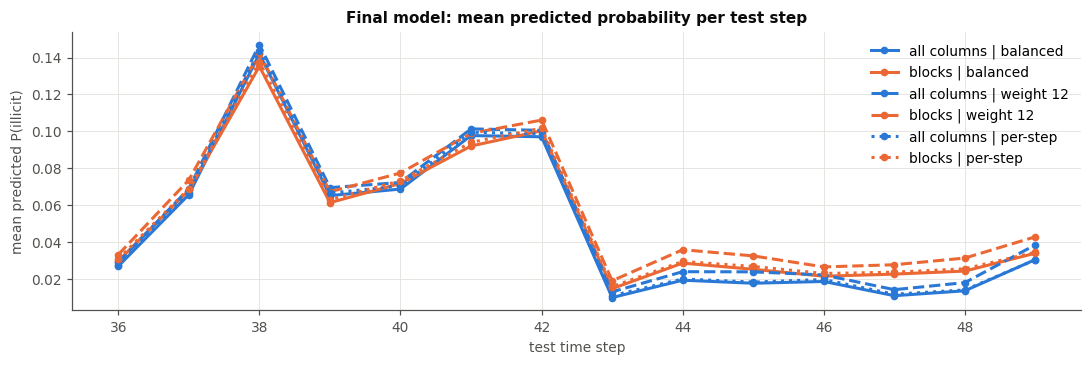

mean predicted P(illicit): steps 36-42 0.082, steps 43-49 0.023


In [13]:
def plot_test_predictions(bags: Dict[str, np.ndarray], steps: np.ndarray) -> pd.DataFrame:
    # Mean predicted P(illicit) per test step for each member: colour = variant, line style = class weight
    per_step = pd.DataFrame(bags).groupby(steps).mean()
    fig, ax = plt.subplots(figsize=(10, 3.4))
    variants = list(dict.fromkeys(name.split(" | ")[0] for name in per_step))
    weights = list(dict.fromkeys(name.split(" | ")[1] for name in per_step))
    for name, values in per_step.items():
        variant, weight = name.split(" | ")[:2]                 # a third part, "<k> steps", marks an extra window
        ax.plot(per_step.index, values, color=(BLUE, ORANGE)[variants.index(variant) % 2], lw=2, marker="o", ms=4,
                ls=("-", "--", ":")[weights.index(weight) % 3], alpha=1.0 if name.count(" | ") == 1 else 0.45,
                label=name.replace("_", " "))
    ax.set_xlabel("test time step")
    ax.set_ylabel("mean predicted P(illicit)")
    ax.set_title("Final model: mean predicted probability per test step")
    ax.legend(loc="upper right")
    fig.tight_layout()
    plt.show()
    return per_step.round(3)


test_per_step = plot_test_predictions(bags, test.time_step.to_numpy())
pre, post = test_per_step.loc[:42].mean(), test_per_step.loc[43:].mean()
print(f"mean predicted P(illicit): steps 36-42 {pre.mean():.3f}, steps 43-49 {post.mean():.3f}")

From step 43 the model predicts almost no fraud: the mean predicted probability drops by roughly an order of
magnitude, and every model built in this project shows the same drop. The data alone cannot say why; two
leaderboard probes *(recorded)* say the drop is right rather than a blind spot. Replacing each score by its rank
*within* its step (erasing the level difference between periods) cost −0.022, and amplifying the level difference
cost −0.0015: the model places the periods relative to each other about right. Placing every step-43+ transaction
below every earlier one cost −0.071, so the late block still contains fraud that the model ranks above most licit
transactions.

## Summary

| decision | choice | evidence |
|---|---|---|
| missing values | none in features; unlabelled rows not used; missing neighbour statistics left to LightGBM | section 1.1 |
| removed features | six period identifiers | per-step drift and out-of-range test values (section 1.3) |
| training rows | labelled rows of the last 14 steps | public 0.9484 vs 0.9437 for all history |
| graph features | neighbour scores + neighbour feature means over labelled one-hop neighbours | homophily (section 1.4); public +0.004, +0.0022, +0.0011 |
| model | two-stage LightGBM, component-grouped out-of-fold scores, random split thresholds in model B | public 0.9671 / 0.9663 per variant (unweighted) |
| imbalance | illicit rows up-weighted in model B (5.6 = balanced, 12, per-step balance; all three averaged); fixed rounds; AUC and PR-AUC reported | public 0.9671 → 0.9692–0.9700 (all columns); not visible on validation (section 2.4) |
| final | rank average of 2 model-B variants × 3 class weightings, 15 seeds each | public **0.97066** |
| second selection | the two variants at the balanced class weight (2 members) | public 0.97020; `class_weights = {"balanced": ...}` (section 3.3) |